In [7]:
import pandas as pd
import matplotlib.pyplot as plt

tea = pd.read_csv("student_tea_snacks _1_.csv")
print(tea.shape)


(100, 7)


In [8]:
print(tea.isna().sum())



student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64


In [9]:
print("Duplicate rows:", tea.duplicated().sum())


Duplicate rows: 0


In [10]:
tea.head()

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4


In [11]:
print(tea["tea_type"].value_counts(dropna=False))
print("Most preferred:", tea["tea_type"].value_counts().idxmax())

tea_type
Green          29
Doodh Patti    25
Black          23
NaN            23
Name: count, dtype: int64
Most preferred: Green


In [12]:
print(tea.groupby("gender")["cups_per_day"].agg(["count", "mean", "median"]).round(2))

        count  mean  median
gender                     
Female     47   2.6     3.0
Male       53   3.0     3.0


snack_choice
Samosa     40
Chips      31
Biscuit    29
Name: count, dtype: int64


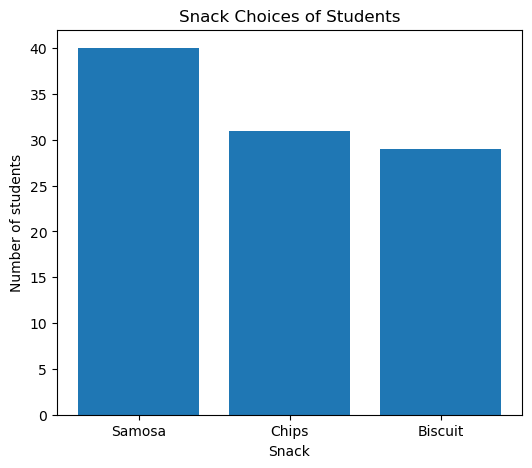

In [13]:
snacks = tea["snack_choice"].value_counts()
print(snacks)

plt.figure(figsize=(6, 5))
plt.bar(snacks.index, snacks.values)
plt.title("Snack Choices of Students")
plt.xlabel("Snack")
plt.ylabel("Number of students")
plt.show()

In [14]:
print(pd.crosstab(tea["age_group"], tea["prefers_tea"]))
print()
print((pd.crosstab(tea["age_group"], tea["prefers_tea"], normalize="index") * 100).round(1))

prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16

prefers_tea    No   Yes
age_group              
18-20        48.7  51.3
21-23        53.1  46.9
24-26        44.8  55.2


In [15]:
print("prefers_tea = No:", (tea["prefers_tea"] == "No").sum())
print("cups_per_day = 0:", (tea["cups_per_day"] == 0).sum())
print("Both No and 0 cups:", ((tea["prefers_tea"] == "No") & (tea["cups_per_day"] == 0)).sum())

prefers_tea = No: 49
cups_per_day = 0: 13
Both No and 0 cups: 8
